# exp3_fixed_baselines — non-learning reference points

Two non-learning policies, requested by **both** reviewers as "missing
essential experimental baselines": `random_policy` (uniform 50/50 action
every step) and `always_exploit` (act 1 — try to eat — every step). A third
policy, `always_abstain`, is implemented in `FixedPolicyAgent` (see
`agent_policies_gt_ais.py`) but is not part of the default run set; §6 comes
back to why it may still be worth adding.

**Why these two matter.** Every other notebook in this folder reports a
*learned* policy's depletion step and Gini coefficient. Those numbers are
only interpretable against some reference — is a DQN agent under condition D
actually doing something more sophisticated than acting without any
strategy at all?

- **`always_exploit`** is the **fastest possible depletion**: every one of
  the 6 agents tries to eat on every step, so it lower-bounds how long the
  shared pool can survive under this environment's stochastic dynamics
  (`env_gt_ais.py`: success probability = `r_t / r_0`, so consumption
  pressure — and the episode length it produces — is a property of the
  environment, not of any policy's cleverness).
- **`random_policy`** is a **neutral, uninformed** policy: whatever resource
  lifetime and meal distribution it produces reflects chance alone, with no
  strategy of any kind — cooperative or selfish.

A learned condition should fall on the sustainable side of `always_exploit`;
whether it also does better than pure chance (`random_policy`), and how its
Gini coefficient compares to both, is what tells you learning bought
something beyond doing nothing in particular.

**No hypothesis test is really the point here.** `FixedPolicyAgent.step()`
(see `agent_policies_gt_ais.py`) just re-applies the fixed rule every step —
there is no learning, hence no learning curve, no "end of training" window,
and no factor to run an ANOVA over. This notebook is a **calibration
table**: two numbers meant to sit next to the learned conditions'
results in the other notebooks, not a result in its own right.

## 1. Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

EXPERIMENT = "exp3_fixed_baselines"
RESULTS_DIR = Path("..") / "csv_results" / EXPERIMENT

ALPHA_LEVEL = 0.05
TARGET_SEEDS = 20   # replications requested by R2 (see EXPERIMENT_TRACKER.md)

print(f"experiment : {EXPERIMENT}")
print(f"data       : {RESULTS_DIR.resolve()}")

experiment : exp3_fixed_baselines
data       : C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\02_GT_AIS\csv_results\exp3_fixed_baselines


In [2]:
# chart chrome: recessive grid and axes, text in neutral ink, series colour
# reserved for the marks themselves. Lighter than exp1/exp6's palette block
# since this notebook has at most one figure.
SURFACE = "#fcfcfb"
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": INK["baseline"], "axes.linewidth": 1.0,
    "axes.labelcolor": INK["secondary"], "axes.labelsize": 10,
    "axes.titlecolor": INK["primary"], "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "text.color": INK["primary"], "legend.frameon": False, "legend.fontsize": 9,
})

METRIC_LABEL = {
    "depletion_step": "Depletion step (steps before the pool empties)",
    "gini_meals": "Gini coefficient of meals",
    "total_meals": "Total meals consumed per episode",
}

METRICS = ["depletion_step", "gini_meals"]


def stars(p: float) -> str:
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"

## 2. Load the runs

In [3]:
def load_summaries(results_dir: Path) -> pd.DataFrame:
    """Concatenate every *_episode_summary.csv of one experiment folder.

    The runner writes all condition parameters as columns (main_gt_ais.py,
    summary_header()), so no filename parsing is needed.
    """
    files = sorted(results_dir.glob("*_episode_summary.csv"))
    if not files:
        raise FileNotFoundError(f"no *_episode_summary.csv under {results_dir.resolve()}")
    frames = []
    for path in files:
        one = pd.read_csv(path)
        one["source_file"] = path.name
        frames.append(one)
    return pd.concat(frames, ignore_index=True)


df = load_summaries(RESULTS_DIR)
print(f"{df['source_file'].nunique()} run files, {len(df)} episode rows\n")

inventory = (
    df.groupby("condition", observed=True)
      .agg(seeds=("seed", "nunique"), runs=("source_file", "nunique"),
           eval_episodes=("phase", lambda s: int((s == "eval").sum())))
      .sort_index()
)
inventory["seeds_missing_vs_target"] = TARGET_SEEDS - inventory["seeds"]
display(inventory)

16 run files, 8800 episode rows



,seeds,runs,eval_episodes,seeds_missing_vs_target
condition,,,,
always_exploit,8,8,400,12
random_policy,8,8,400,12


## 3. Derived metrics and integrity

Same two checks as every other notebook here: duplicated episodes, and
right-censoring of the depletion step (an episode cut off at `max_steps`
with resource left never actually depleted the pool). `always_exploit` is
expected to censor rarely if at all — it is the fastest-depleting policy by
construction; `random_policy` may censor more often.

In [4]:
df["depletion_step"] = df["total_steps"]
df["censored"] = (df["total_steps"] >= df["max_steps"]) & (df["resource_remaining"] > 0)
meal_cols = [c for c in df.columns if re.fullmatch(r"meals_\d+", c)]
df["total_meals"] = df[meal_cols].sum(axis=1)

ev = df[df["phase"] == "eval"].copy()

dupes = int(df.duplicated(subset=["condition", "seed", "phase", "episode"]).sum())
print(f"duplicate (condition, seed, phase, episode) rows : {dupes}")
assert dupes == 0, "duplicated episode rows -- check for a re-run written twice"

censoring = (ev.groupby("condition", observed=True)
               .agg(eval_episodes=("censored", "size"), censored_rate=("censored", "mean"))
               .sort_index())
display(censoring.style.format({"censored_rate": "{:.1%}"}))

duplicate (condition, seed, phase, episode) rows : 0


,eval_episodes,censored_rate
condition,,
always_exploit,400,0.5%
random_policy,400,66.8%


## 4. Aggregation: all eval episodes, not just the last N

Every other notebook in this folder averages only the **last** `LAST_N_EVAL`
greedy evaluation episodes per seed, because a learning agent's early
episodes are not representative of its converged policy. That reasoning does
not apply here: a `FixedPolicyAgent` never changes, so *every* eval episode
is an equally valid, independent sample of the fixed policy under the
environment's stochastic dynamics. Restricting to the last few episodes
would only throw away data for no benefit — so this notebook aggregates over
**all** eval episodes per seed instead. The unit of analysis is still one row
per (condition, seed).

In [5]:
seed_df = (ev.groupby(["condition", "seed"], observed=True)
             .agg(depletion_step=("depletion_step", "mean"),
                  gini_meals=("gini_meals", "mean"),
                  total_meals=("total_meals", "mean"),
                  censored_frac=("censored", "mean"),
                  n_eval=("episode", "size"))
             .reset_index())

print(f"{len(seed_df)} seed-level rows ({seed_df['n_eval'].min()}-{seed_df['n_eval'].max()} "
      f"eval episodes averaged per seed)")

summary = seed_df.groupby("condition", observed=True)[METRICS].agg(["mean", "std", "count"])
display(summary.style.format("{:.3f}"))

16 seed-level rows (50-50 eval episodes averaged per seed)


## 5. Sanity checks

Two directional predictions follow directly from the policies' definitions,
not from any theory being tested — they are here to confirm the pipeline
(environment, logging, the two metrics) behaves as expected before anyone
trusts a learned-agent comparison against these numbers:

1. `always_exploit` should have a **shorter** depletion step than
   `random_policy` — maximal constant pressure on the pool versus half the
   pressure on average.
2. Gini is harder to sign a priori for two *homogeneous* populations (all 6
   agents run the identical fixed policy, so within-episode inequality comes
   from the stochastic success draws alone, not from any strategic
   asymmetry) — reported for completeness rather than as a directional
   prediction.

In [6]:
for metric in METRICS:
    a = seed_df.loc[seed_df["condition"] == "always_exploit", metric].to_numpy()
    r = seed_df.loc[seed_df["condition"] == "random_policy", metric].to_numpy()
    u, p = stats.mannwhitneyu(a, r, alternative="two-sided")
    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}")
    print(f"  always_exploit : {a.mean():8.3f}  (n={len(a)})")
    print(f"  random_policy  : {r.mean():8.3f}  (n={len(r)})")
    print(f"  Mann-Whitney U = {u:.1f}, p = {p:.4f} {stars(p)}")

pred = (seed_df.groupby("condition", observed=True)["depletion_step"].mean()
              .loc["always_exploit"] < seed_df.groupby("condition", observed=True)
              ["depletion_step"].mean().loc["random_policy"])
print("\n" + "-" * 78)
print(f"prediction 1 (always_exploit depletes faster than random_policy): "
      f"{'confirmed' if pred else 'NOT confirmed -- check the pipeline'}")

Depletion step (steps before the pool empties)
  always_exploit :  564.910  (n=8)
  random_policy  :  969.455  (n=8)
  Mann-Whitney U = 0.0, p = 0.0002 ***
Gini coefficient of meals
  always_exploit :    0.037  (n=8)
  random_policy  :    0.044  (n=8)
  Mann-Whitney U = 0.0, p = 0.0002 ***

------------------------------------------------------------------------------
prediction 1 (always_exploit depletes faster than random_policy): confirmed


## 6. Figure

findfont: Failed to find font weight semibold, now using 700.


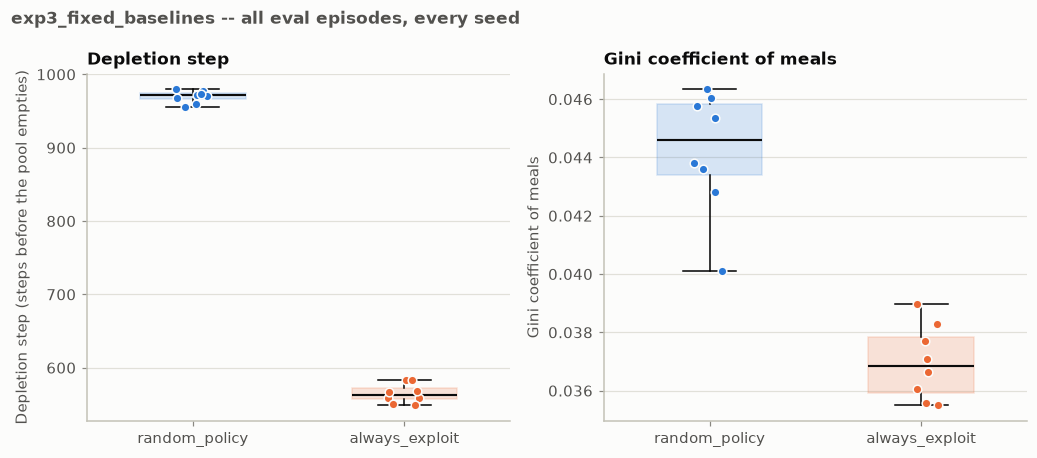

In [7]:
order = ["random_policy", "always_exploit"]
colors = {"random_policy": CAT[0], "always_exploit": CAT[1]}
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, metric in zip(axes, METRICS):
    boxes = [seed_df.loc[seed_df["condition"] == c, metric].to_numpy() for c in order]
    bp = ax.boxplot(boxes, positions=range(len(order)), widths=0.5, showfliers=False,
                    patch_artist=True)
    for patch, c in zip(bp["boxes"], order):
        patch.set_facecolor(colors[c]); patch.set_alpha(0.18); patch.set_edgecolor(colors[c])
    for med in bp["medians"]:
        med.set_color(INK["primary"]); med.set_linewidth(1.4)
    for i, c in enumerate(order):
        vals = seed_df.loc[seed_df["condition"] == c, metric].to_numpy()
        ax.scatter(i + rng.uniform(-0.08, 0.08, len(vals)), vals, s=32,
                   color=colors[c], edgecolor=SURFACE, linewidth=1.0, zorder=3)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    ax.set_title(METRIC_LABEL[metric].split(" (")[0])
    ax.set_ylabel(METRIC_LABEL[metric])
fig.suptitle("exp3_fixed_baselines -- all eval episodes, every seed", x=0.012, ha="left",
             fontsize=11, fontweight="semibold", color=INK["secondary"])
fig.tight_layout()
plt.show()

## 7. Caveats

- **Reference values only.** Nothing here is a claim about empathy or
  learning — these two rows exist to be quoted by the other notebooks when
  they ask "is condition X better than doing nothing in particular?".
- **`always_abstain` is not run.** It would trivially never deplete the pool
  and never generate any Gini signal (no meals at all), so it adds little as
  a *depletion-step* reference — but `EXPERIMENT_TRACKER.md` flags it as the
  relevant comparison for `exp6`'s α = 0.99 caveat (distinguishing a
  genuinely sustainable policy from one where the empathic term has simply
  extinguished the incentive to eat). `exp4`'s read-out below in this folder
  (see `analysis_exp4_inequity_aversion.ipynb`) runs into the same
  near-abstention pattern from a different mechanism, which is why that
  comparison matters beyond `exp6` alone.
- **Homogeneous populations.** All 6 agents share the same fixed policy in
  both conditions, so the Gini values above measure pure stochastic variance
  in who happens to succeed, not any strategic inequality — a different
  quantity from the Gini reported for heterogeneous / learned populations
  elsewhere.